In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import numpy as np
import math

In [ ]:
# Load World Happiness data (2015-2019)
happiness_df = pd.read_csv("../../data/processed/world_happiness_2015_2019_clean.csv")

# Structural overview
print(f"Dataset shape: {happiness_df.shape}")
print("-" * 50)
happiness_df.info()

Dataset shape: (782, 10)
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 782 entries, 0 to 781
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   country                    782 non-null    object 
 1   year                       782 non-null    int64  
 2   happiness_rank             782 non-null    int64  
 3   happiness_score            782 non-null    float64
 4   gdp_per_capita             782 non-null    float64
 5   social_support             782 non-null    float64
 6   healthy_life_expectancy    782 non-null    float64
 7   freedom                    782 non-null    float64
 8   generosity                 782 non-null    float64
 9   perceptions_of_corruption  782 non-null    float64
dtypes: float64(7), int64(2), object(1)
memory usage: 61.2+ KB


In [3]:
happiness_df.isnull().sum()

country                      0
year                         0
happiness_rank               0
happiness_score              0
gdp_per_capita               0
social_support               0
healthy_life_expectancy      0
freedom                      0
generosity                   0
perceptions_of_corruption    0
dtype: int64

In [4]:
duplicated_values = happiness_df.duplicated()
duplicated_values.sum()

np.int64(0)

In [5]:
display(happiness_df.select_dtypes(include='number').describe().T)

,count,mean,std,min,25%,50%,75%,max
year,782.0,2016.993606,1.417364,2015.000,2016.000000,2017.000000,2018.000000,2019.000000
happiness_rank,782.0,78.698210,45.182384,1.000,40.000000,79.000000,118.000000,158.000000
happiness_score,782.0,5.379018,1.127456,2.693,4.509750,5.322000,6.189500,7.769000
gdp_per_capita,782.0,0.916047,0.407340,0.000,0.606500,0.982205,1.236187,2.096000
social_support,782.0,1.078392,0.329548,0.000,0.869363,1.124735,1.327250,1.644000
healthy_life_expectancy,782.0,0.612416,0.248309,0.000,0.440183,0.647310,0.808000,1.141000
freedom,782.0,0.411091,0.152880,0.000,0.309768,0.431000,0.531000,0.724000
generosity,782.0,0.218576,0.122321,0.000,0.130000,0.201982,0.278832,0.838075
perceptions_of_corruption,782.0,0.125599,0.105847,0.000,0.054250,0.091033,0.156243,0.551910


The integrated dataset comprises a total of 164 countries across the 2015-2019 period. Of these, 146 countries (89.02%) have complete data for all 5 years, while only 18 countries have partial records. The average data coverage per country is 4.76 years. This high completeness rate (89%) ensures that the historical trends and outlier analysis are statistically robust and representative of the global landscape

In [6]:
# Country participation summary

# Build a clean country participation table from the current happiness dataset
expected_years = sorted(happiness_df["year"].dropna().unique())

country_participation_clean = (
    happiness_df
    .groupby("country", as_index=False)
    .agg(participation_count=("year", "nunique"))
    .assign(
        participation_status=lambda df: df["participation_count"].apply(
            lambda count: "Complete" if count == len(expected_years) else "Incomplete"
        )
    )
)

participation_summary = pd.Series({
    "Total countries": country_participation_clean["country"].nunique(),
    "Complete countries": (
        country_participation_clean["participation_status"]
        .eq("Complete").sum()
    ),
    "Incomplete countries": (
        country_participation_clean["participation_status"]
        .eq("Incomplete").sum()
    ),
    "Average years per country": (
        country_participation_clean["participation_count"].mean()
    ),
    "Median years per country": (
        country_participation_clean["participation_count"].median()
    ),
    "Complete coverage (%)": (
        country_participation_clean["participation_status"]
        .eq("Complete").mean() * 100
    )
})

display(participation_summary.to_frame("Value"))

,Value
Total countries,164.000000
Complete countries,146.000000
Incomplete countries,18.000000
Average years per country,4.768293
Median years per country,5.000000
Complete coverage (%),89.024390


/tmp/ipykernel_10880/1535970733.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


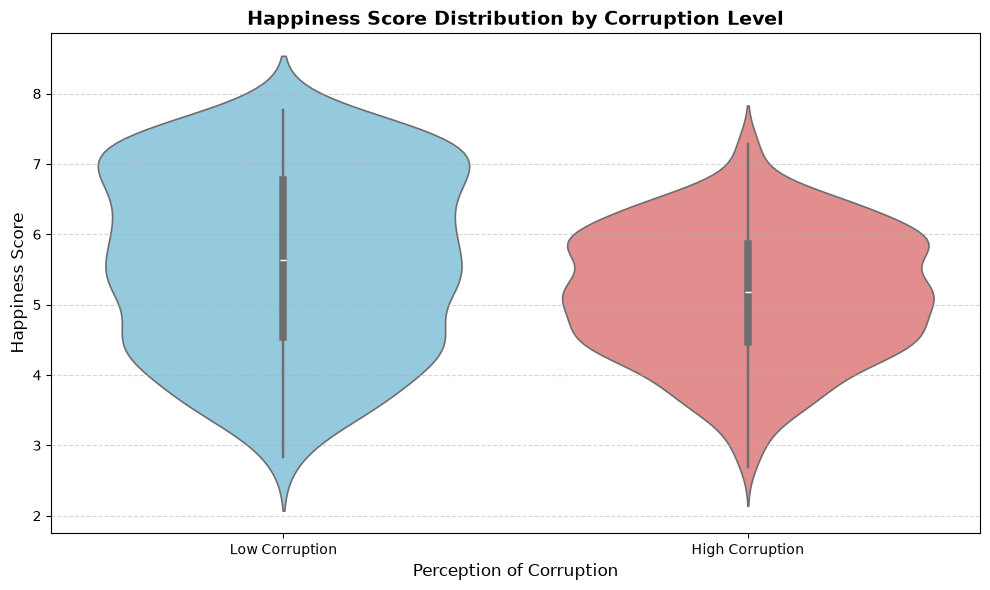

In [7]:

df = happiness_df.copy()

# 1. Create the category (Split by the median of corruption)
median_corruption = df['perceptions_of_corruption'].median()

df['Corruption_Level'] = df['perceptions_of_corruption'].apply(
    lambda x: 'High Corruption' if x < median_corruption else 'Low Corruption'
)

# 2. Plot the Violin Plot
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x="Corruption_Level",
    y="happiness_score",
    palette={"High Corruption": "lightcoral", "Low Corruption": "skyblue"},
    inner="box",       # Shows the boxplot inside the violin
    linewidth=1.2
)

# 3. Customization
plt.title("Happiness Score Distribution by Corruption Level", fontsize=14, fontweight='bold')
plt.xlabel("Perception of Corruption", fontsize=12)
plt.ylabel("Happiness Score", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

/tmp/ipykernel_10880/4014272924.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


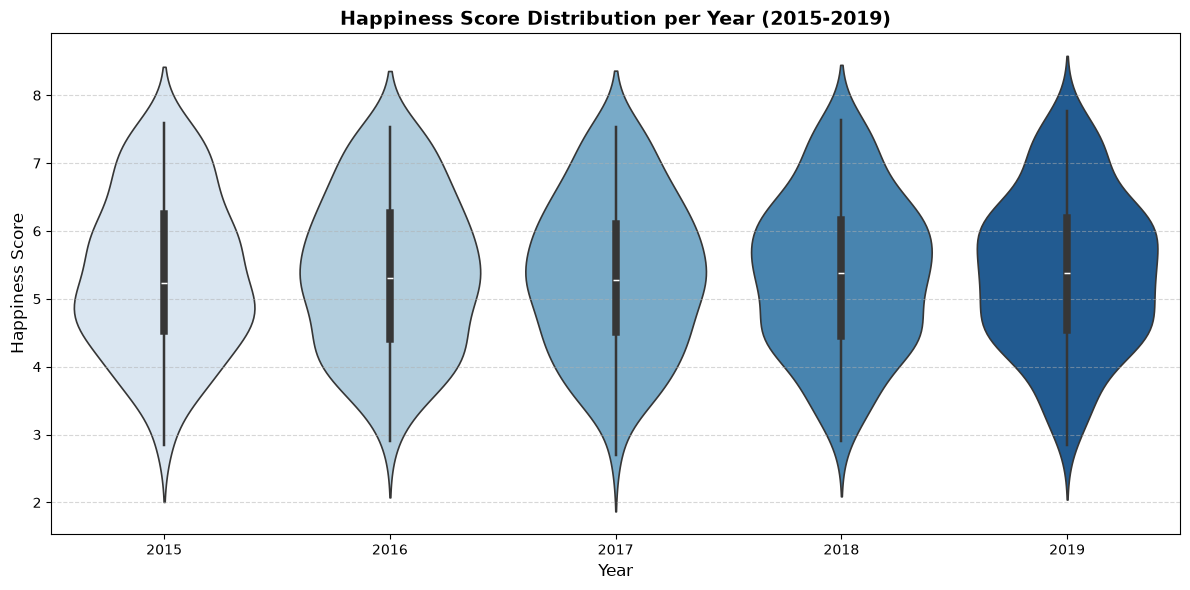

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt


df = happiness_df.copy()

# 1. Create the Violin Plot
plt.figure(figsize=(12, 6))

sns.violinplot(
    data=df,
    x="year",               # Assuming you have a 'year' column in your unified dataset
    y="happiness_score",
    palette="Blues",
    inner="box",            # Shows the box (Q1, median, Q3) inside the violin
    linewidth=1.2
)

# 2. Customization
plt.title("Happiness Score Distribution per Year (2015-2019)", fontsize=14, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Happiness Score", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

/tmp/ipykernel_10880/4127064521.py:26: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group[features + [target]].corr()[target][features])


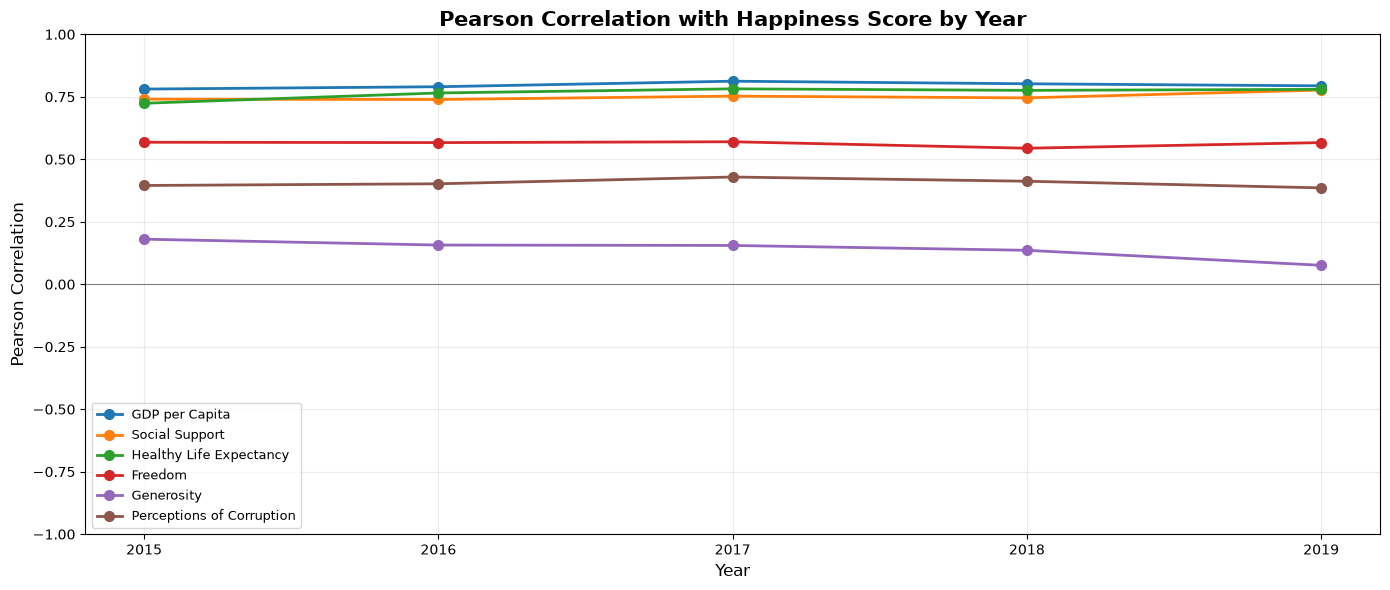

In [9]:

# Variables
target = "happiness_score"

features = [
    "gdp_per_capita",
    "social_support",
    "healthy_life_expectancy",
    "freedom",
    "generosity",
    "perceptions_of_corruption"
]

# Feature labels in English
feature_labels = {
    "gdp_per_capita": "GDP per Capita",
    "social_support": "Social Support",
    "healthy_life_expectancy": "Healthy Life Expectancy",
    "freedom": "Freedom",
    "generosity": "Generosity",
    "perceptions_of_corruption": "Perceptions of Corruption"
}

# Calculate Pearson correlations by year
correlations = (
    happiness_df.groupby("year")
    .apply(lambda group: group[features + [target]].corr()[target][features])
)

# Create figure
fig, ax = plt.subplots(figsize=(14, 6))

# Plot each feature
for feature in features:
    ax.plot(
        correlations.index,
        correlations[feature],
        marker="o",
        linewidth=2,
        markersize=7,
        label=feature_labels[feature]
    )

# Formatting
ax.set_title(
    "Pearson Correlation with Happiness Score by Year",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Pearson Correlation", fontsize=12)

ax.set_ylim(-1, 1)
ax.set_xticks(correlations.index)

ax.axhline(y=0, color="gray", linewidth=0.8)
ax.grid(True, alpha=0.25)

ax.legend(
    loc="lower left",
    fontsize=9,
    frameon=True
)

plt.tight_layout()
plt.show()


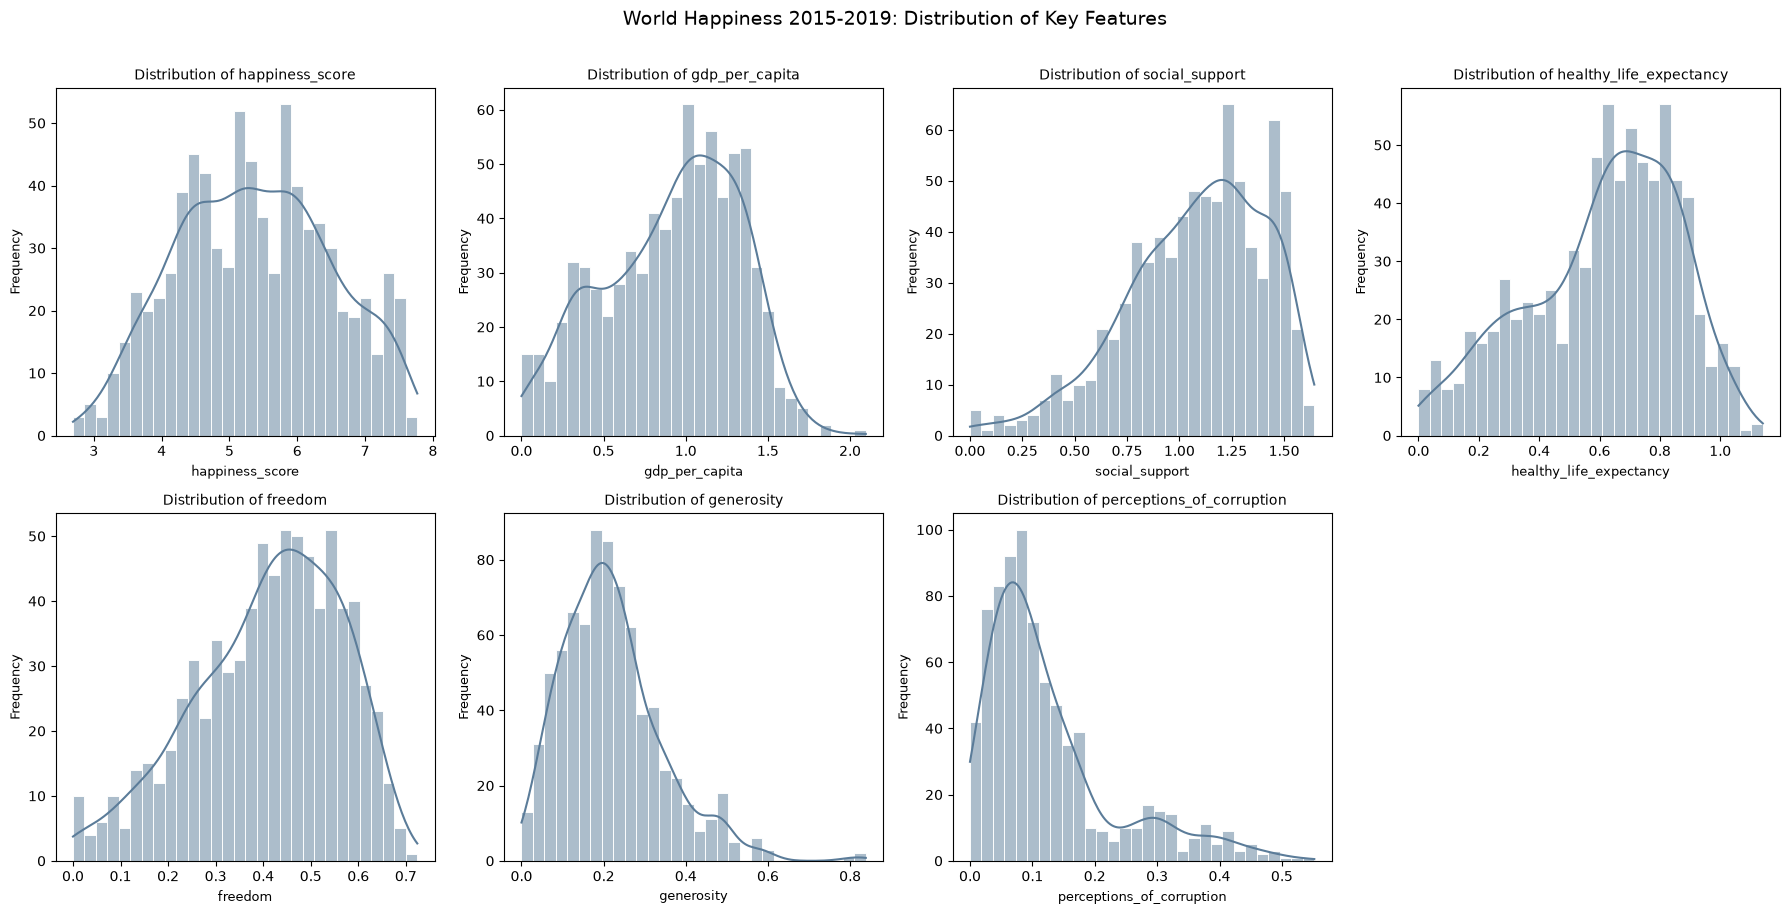

In [10]:
# 1. Auto-detect numeric columns
numeric_cols = happiness_df.select_dtypes(include=['number']).columns.tolist()

# 2. Exclude columns not relevant for distribution analysis
exclude_keywords = [
    'rank',
    'year',
    'confidence interval'
]

numeric_cols = [
    col for col in numeric_cols
    if not any(keyword in col.lower() for keyword in exclude_keywords)
]

# 3. Create figure and axes grid
n = len(numeric_cols)
ncols = 4
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(18, 4.5 * nrows)
)

axes = axes.flatten()

# 4. Plot distributions
for i, feature in enumerate(numeric_cols):
    sns.histplot(
        happiness_df[feature].dropna(),
        bins=30,
        kde=True,
        ax=axes[i],
        color="#5b7c99",
        edgecolor="white"
    )

    axes[i].set_title(f"Distribution of {feature}", fontsize=10)
    axes[i].set_xlabel(feature, fontsize=9)
    axes[i].set_ylabel("Frequency", fontsize=9)

# 5. Hide unused subplots
for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle(
    "World Happiness 2015-2019: Distribution of Key Features",
    fontsize=14,
    y=1.01
)

plt.tight_layout()
plt.show()

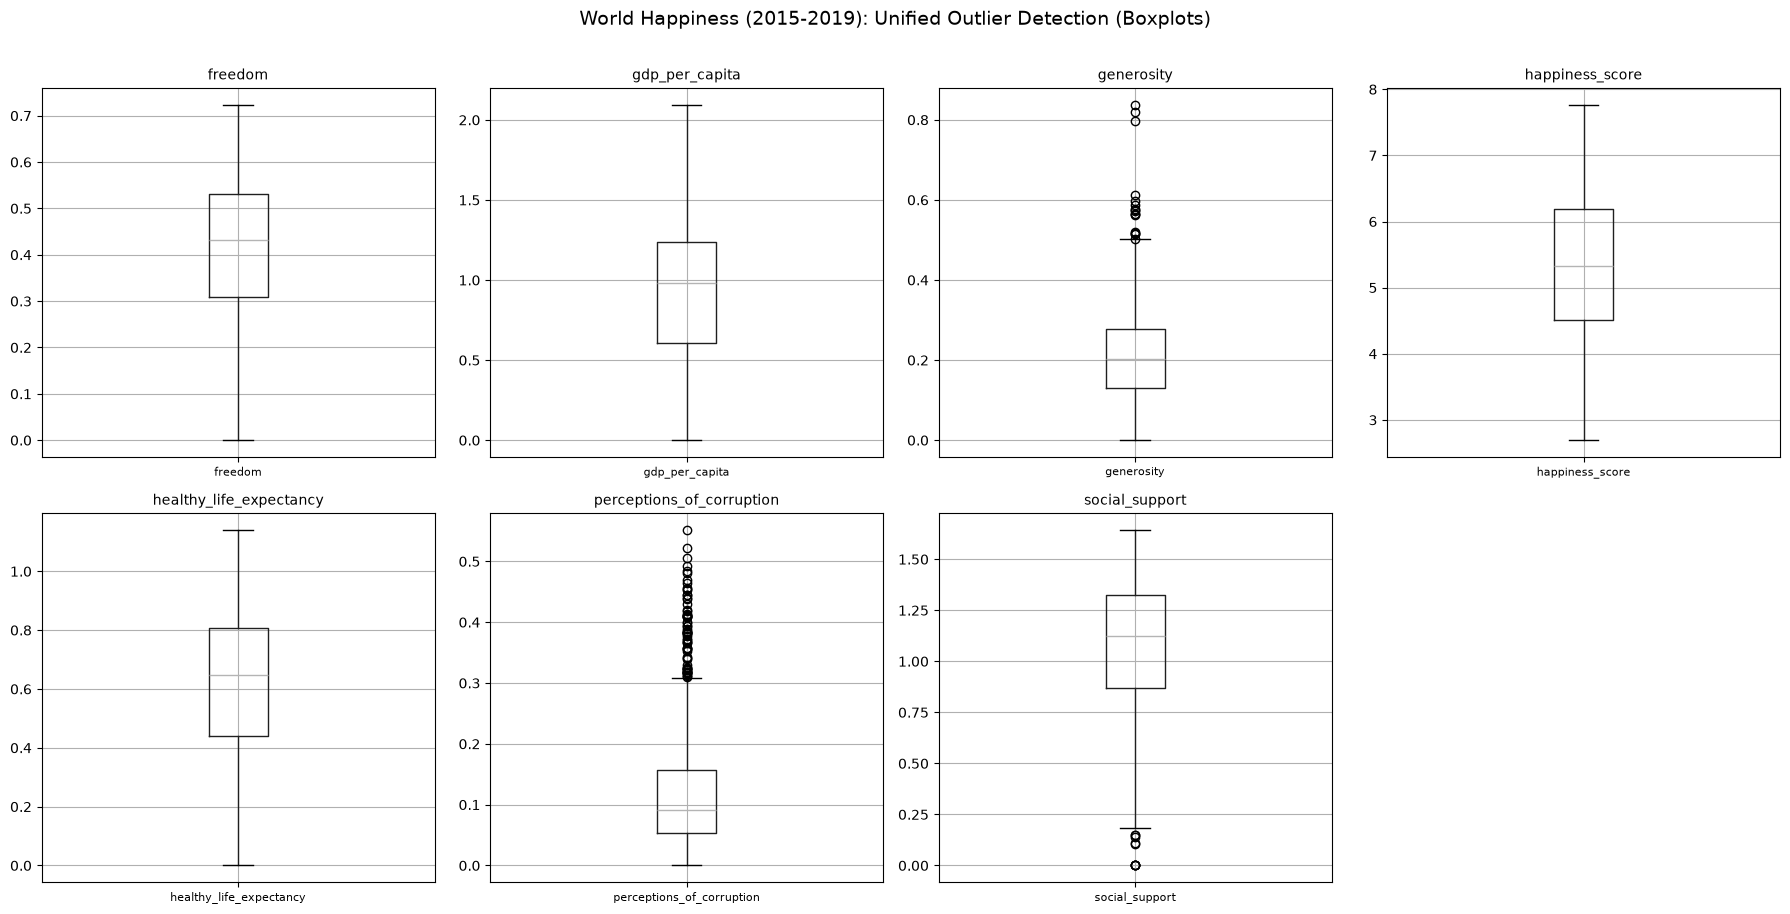

In [11]:
# Auto-detect numeric columns, excluding unnecessary variables
cols_to_drop = [
    'year',
    'happiness_rank'
]

numeric_cols = (
    happiness_df
    .select_dtypes(include=['number'])
    .columns
    .difference(cols_to_drop)
    .tolist()
)

# Create the figure and axes grid
n = len(numeric_cols)
ncols = 4
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(18, 4.5 * nrows)
)

axes = axes.flatten()

# Plot boxplots
for i, col in enumerate(numeric_cols):
    happiness_df.boxplot(column=col, ax=axes[i], vert=True)
    axes[i].set_title(col, fontsize=10)
    axes[i].tick_params(axis="x", labelsize=8)

# Hide unused axes
for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle(
    "World Happiness (2015-2019): Unified Outlier Detection (Boxplots)",
    fontsize=14,
    y=1.01
)

plt.tight_layout()
plt.show()

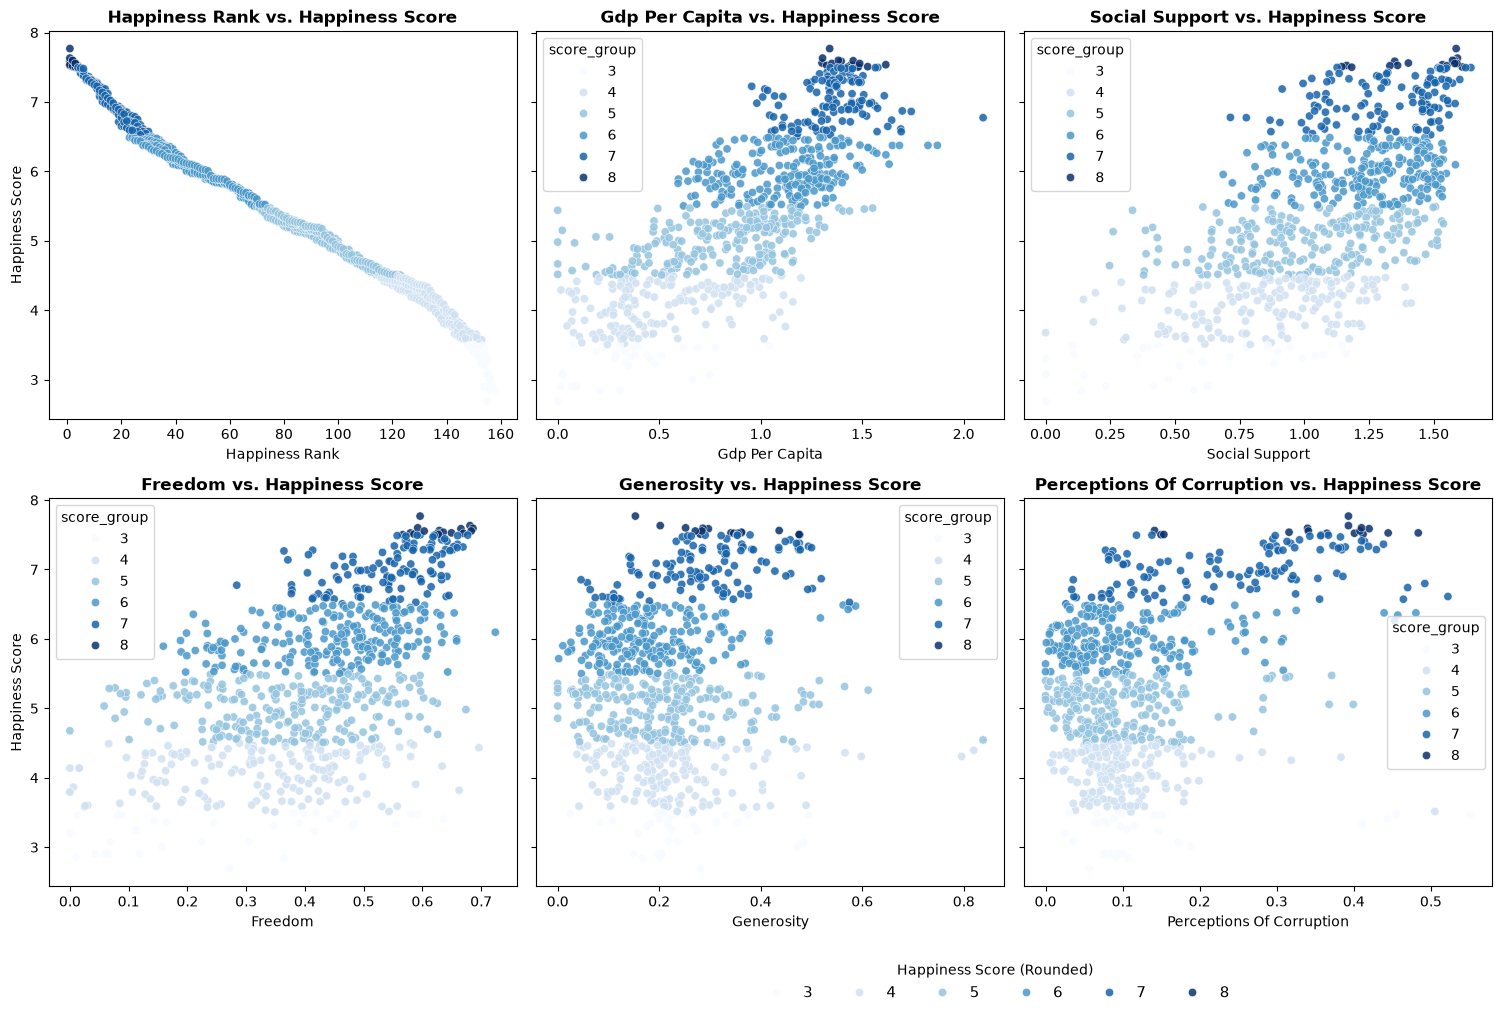

In [12]:


# Features to compare against the happiness score
features = [
    "happiness_rank",
    "gdp_per_capita",
    "social_support",
    "health_life_expectancy",
    "freedom",
    "generosity",
    "perceptions_of_corruption"
]

# Create a copy to preserve the original DataFrame
plot_df = happiness_df.copy()

# Group happiness scores by rounded integer values for color encoding
plot_df["score_group"] = plot_df["happiness_score"].round().astype(int)

# Configure the figure layout (2 rows x 4 columns to fit 7 plots better)
columns = 4
rows = math.ceil(len(features) / columns)

fig, axes = plt.subplots(
    rows,
    columns,
    figsize=(20, 5 * rows),
    sharey=True  # Share the Y axis to make visual comparison easier
)

axes = axes.flatten()

# Generate a scatter plot for each feature
for i, feature in enumerate(features):

    if feature not in plot_df.columns:
        axes[i].set_visible(False)
        continue

    # IMPORTANT: Do NOT pass legend=False here.
    # Seaborn needs to generate the legend handles so we can extract them later.
    sns.scatterplot(
        data=plot_df,
        x=feature,
        y="happiness_score",
        hue="score_group",
        palette="Blues",
        alpha=0.85,
        edgecolor="white",
        linewidth=0.4,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature.replace('_', ' ').title()} vs. Happiness Score", fontsize=12, fontweight='bold')
    axes[i].set_xlabel(feature.replace("_", " ").title())
    axes[i].set_ylabel("Happiness Score")

# Remove unused subplot axes (the 8th empty slot)
for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

# --- Build the shared legend ---
# Extract handles/labels from the first subplot (they all share the same hue mapping)
handles, labels = axes[0].get_legend_handles_labels()

# Remove the individual legend from the first subplot to avoid duplication
axes[0].get_legend().remove()

# Add a single figure-level legend at the bottom
fig.legend(
    handles,
    labels,
    title="Happiness Score (Rounded)",
    loc='lower center',
    ncol=len(labels),            # Put all labels in a single horizontal row
    bbox_to_anchor=(0.5, -0.02), # Center below the figure
    frameon=False,
    fontsize=11
)

# Final layout adjustment: leave 5% space at the bottom for the legend
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

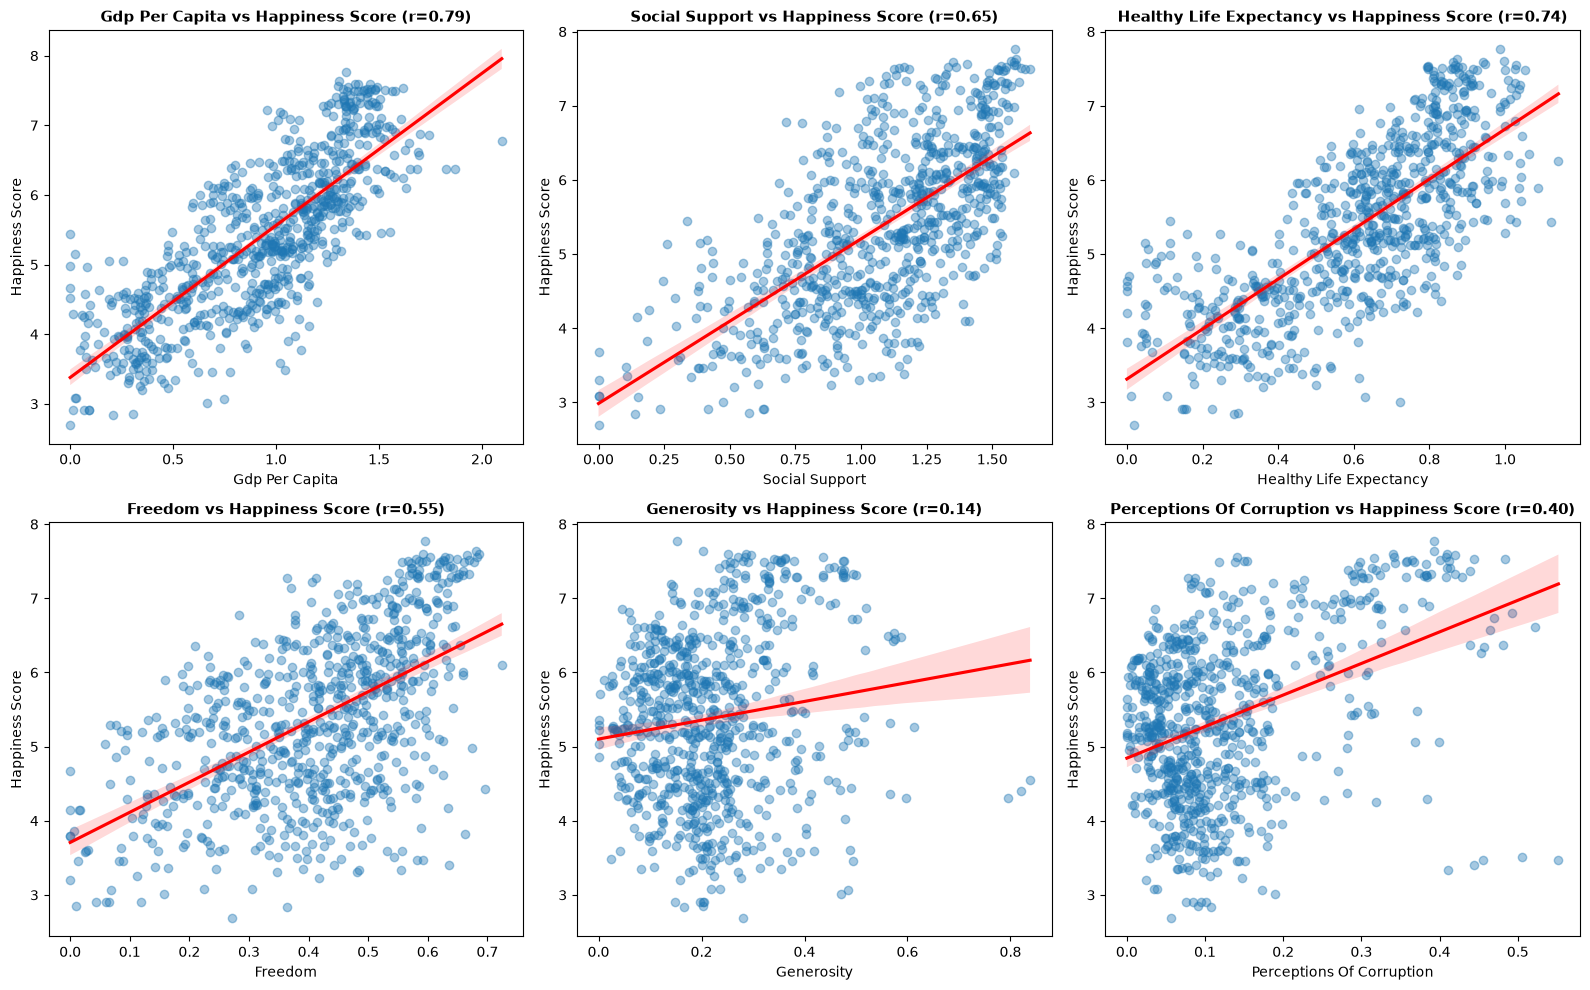

In [13]:

# Variables
target = "happiness_score"

features = [
    "gdp_per_capita",
    "social_support",
    "healthy_life_expectancy",
    "freedom",
    "generosity",
    "perceptions_of_corruption"
]

# DataFrame
df = happiness_df.copy()

# Correlation matrix
corr_matrix = df[features + [target]].corr()

# Create subplots
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

# Generate regression plots
for idx, feat in enumerate(features):
    ax = axes[idx]

    sns.regplot(
        data=df,
        x=feat,
        y=target,
        ax=ax,
        scatter_kws={"alpha": 0.4},
        line_kws={"color": "red"}
    )

    # Correlation coefficient
    r_value = corr_matrix.loc[feat, target]

    # Plot formatting
    ax.set_title(
        f"{feat.replace('_', ' ').title()} vs Happiness Score (r={r_value:.2f})",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_xlabel(feat.replace("_", " ").title())
    ax.set_ylabel("Happiness Score")

# Adjust layout
plt.tight_layout()
plt.show()


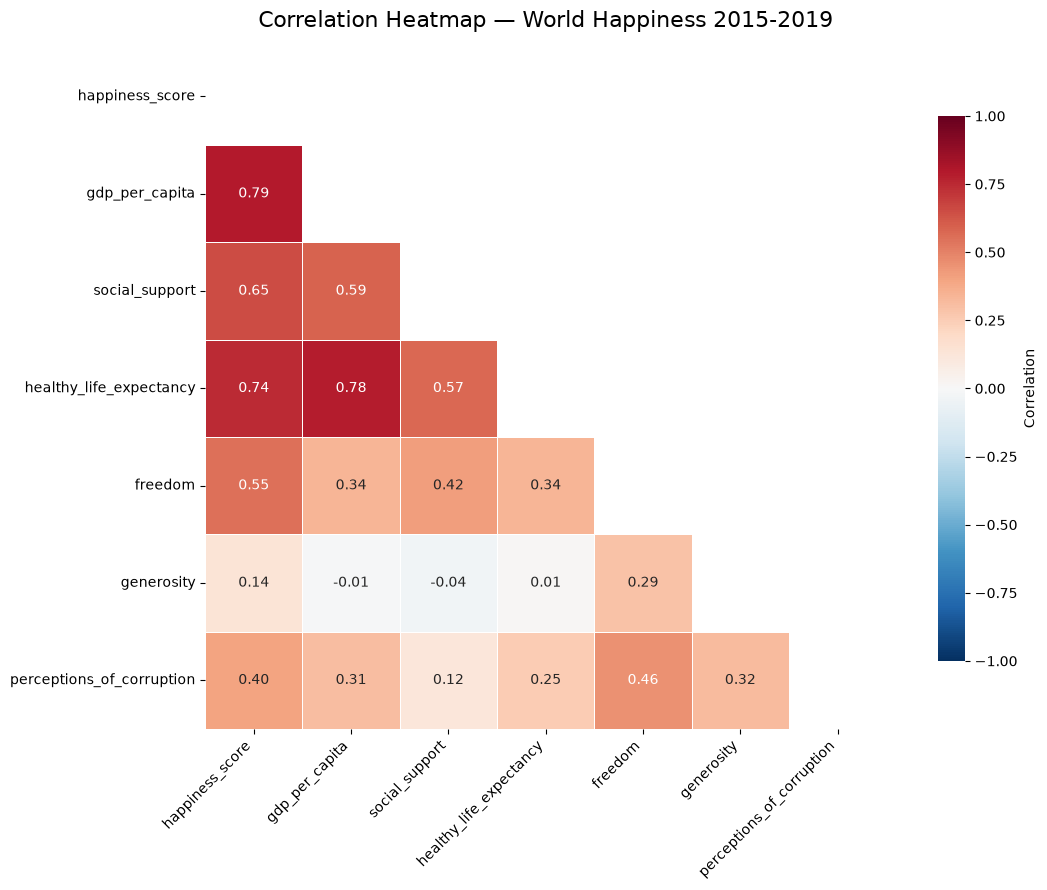

In [14]:
# 1. Select numerical columns
numeric_df = happiness_df.select_dtypes(include="number")

# 2. Exclude columns not relevant for correlation analysis
exclude_keywords = [
    'year',
    'rank',
    'confidence interval'
]

numeric_df = numeric_df[
    [
        col for col in numeric_df.columns
        if not any(keyword in col.lower() for keyword in exclude_keywords)
    ]
]

# 3. Calculate the correlation matrix
corr_matrix = numeric_df.corr()

# 4. Create a mask to display only the lower triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# 5. Plot the heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={
        "shrink": 0.8,
        "label": "Correlation"
    }
)

plt.title(
    "Correlation Heatmap — World Happiness 2015-2019",
    fontsize=16,
    pad=15
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

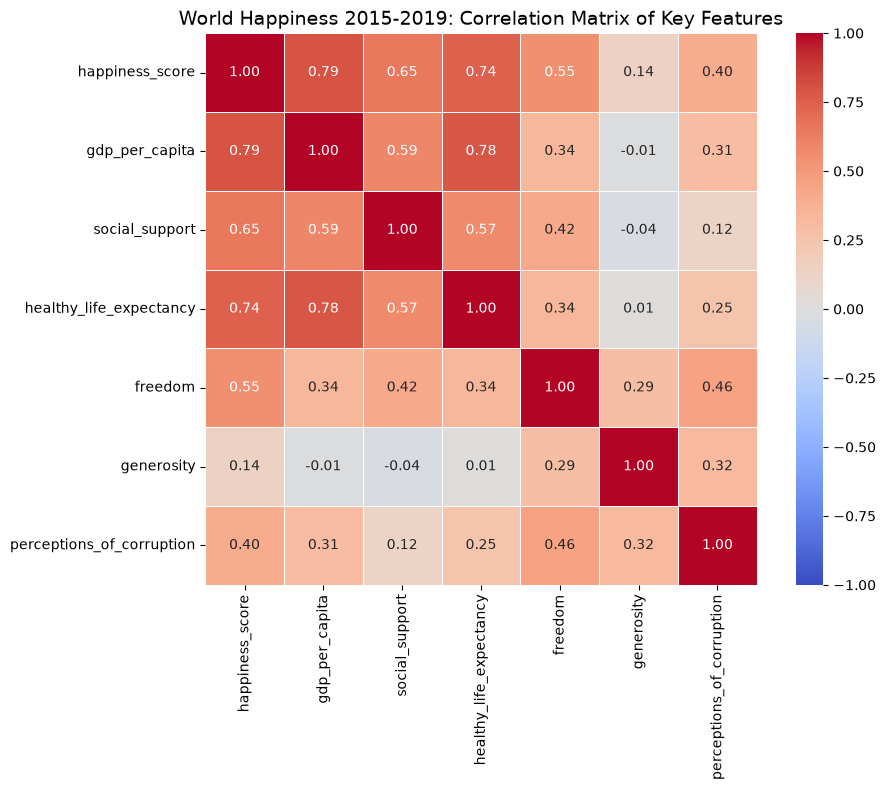

In [15]:
# 1. Select relevant numerical columns
exclude_keywords = [
    'year',
    'rank',
    'confidence interval'
]

clean_cols = [
    col for col in happiness_df.select_dtypes(include='number').columns
    if not any(keyword in col.lower() for keyword in exclude_keywords)
]

# 2. Calculate correlation matrix
corr = happiness_df[clean_cols].corr()

# 3. Plot heatmap
fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    ax=ax,
    square=True,
    linewidths=0.5
)

ax.set_title(
    "World Happiness 2015-2019: Correlation Matrix of Key Features",
    fontsize=14
)

plt.tight_layout()
plt.show()

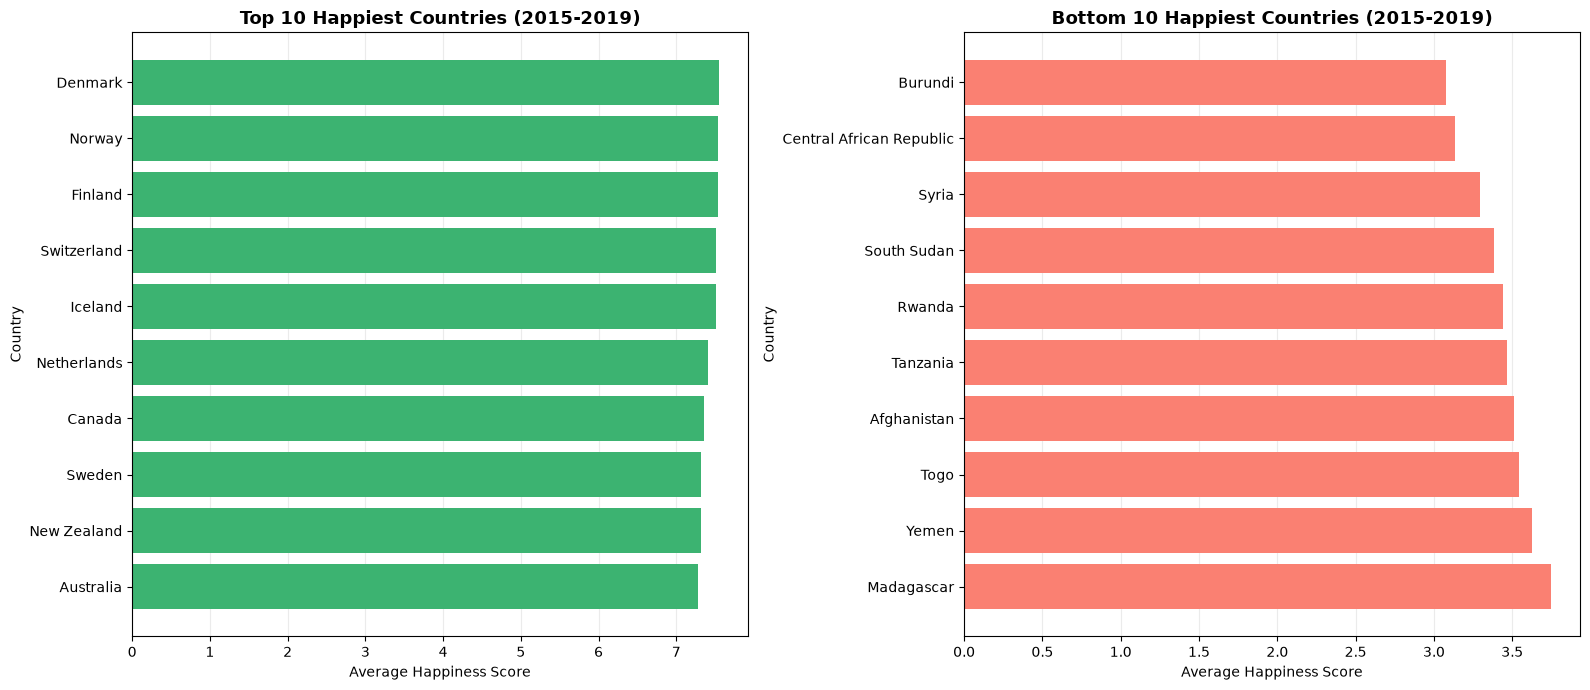

In [16]:

# Calculate average happiness score by country (2015-2019)
country_happiness = (
    happiness_df.groupby("country")["happiness_score"]
    .mean()
    .sort_values(ascending=False)
)

# Select Top 10 and Bottom 10 countries
top_10 = country_happiness.head(10).sort_values()
bottom_10 = country_happiness.tail(10)

# Create figure
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Top 10 Happiest Countries
axes[0].barh(
    top_10.index,
    top_10.values,
    color="mediumseagreen"
)

axes[0].set_title(
    "Top 10 Happiest Countries (2015-2019)",
    fontsize=13,
    fontweight="bold"
)

axes[0].set_xlabel("Average Happiness Score")
axes[0].set_ylabel("Country")

# Bottom 10 Happiest Countries
axes[1].barh(
    bottom_10.index,
    bottom_10.values,
    color="salmon"
)

axes[1].set_title(
    "Bottom 10 Happiest Countries (2015-2019)",
    fontsize=13,
    fontweight="bold"
)

axes[1].set_xlabel("Average Happiness Score")
axes[1].set_ylabel("Country")

# Formatting
for ax in axes:
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


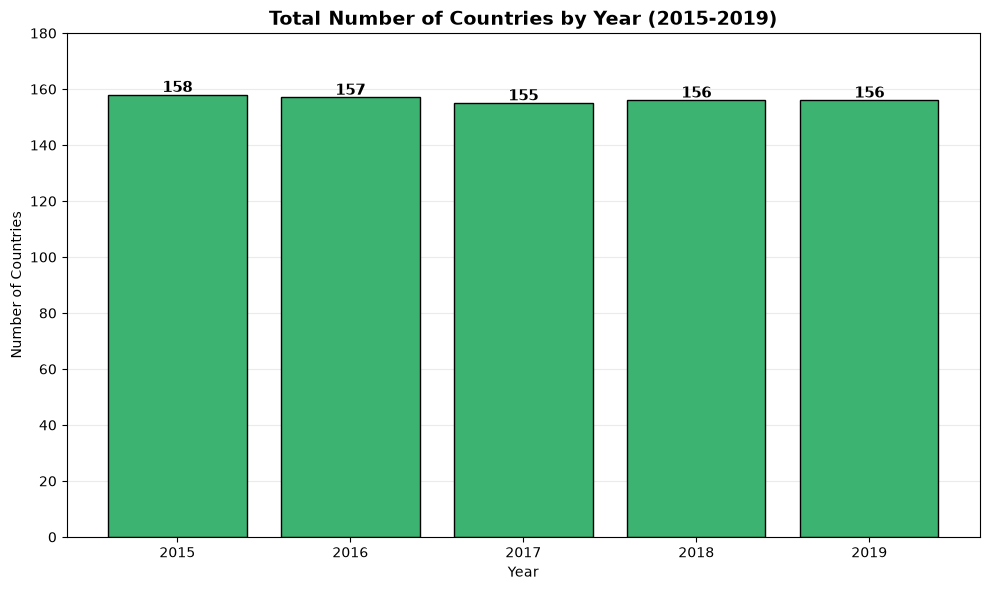

In [17]:

# Total number of countries by year
countries_per_year = happiness_df.groupby("year")["country"].nunique()

# Create figure
plt.figure(figsize=(10, 6))

# Bar chart
bars = plt.bar(
    countries_per_year.index.astype(str),
    countries_per_year.values,
    color="mediumseagreen",
    edgecolor="black"
)

# Add values above each bar
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        int(bar.get_height()),
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

# Formatting
plt.title("Total Number of Countries by Year (2015-2019)",
          fontsize=14, fontweight="bold")
plt.xlabel("Year")
plt.ylabel("Number of Countries")
plt.ylim(0, 180)
plt.grid(axis="y", alpha=0.25)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()
